In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from utils import (get_data, calc_hist, get_rc_and_err, get_rc_and_err_unweighted, get_rc_and_err_new)

In [3]:
EMB_FILE   = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_notrueptcons.root'

COLUMNS   = ['pt', 'b', 'w', 'y1', 'y2', 'phi1', 'phi2',
             'pts', 'bs', 'ws', 'y1s', 'y2s', 'phi1s', 'phi2s', 'nefs']

PT_EDGES  = [15, 20, 25, 30, 40, 60]
PT_CENTERS = [17.5, 22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 2.5, 5, 10]

In [4]:
def bin_df_in_pts(df, col='pts'):
    return [df[(df[col] > PT_EDGES[i]) & (df[col] < PT_EDGES[i+1])] for i in range(5)]

def delta_phi(a, b):
    diff = np.abs(a - b)
    return np.minimum(diff, 2 * np.pi - diff)

def get_rc_and_err_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_rc_and_err_unweighted_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err_unweighted(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

def get_rc_and_err_new_arr(df_arr, ob):
    rc_arr = []
    err_arr = []
    for df in df_arr:
        rc, err = get_rc_and_err_new(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

In [5]:
df_alltrue = get_data(COLUMNS, EMB_FILE, 'MatchedTree').query('pt>15 and b!=-9 and w<1').copy()
df_alltrue['distance1'] = np.sqrt(
    delta_phi(df_alltrue['phi1'].values, df_alltrue['phi1s'].values)**2
    + (df_alltrue['y1'].values - df_alltrue['y1s'].values)**2)
df_alltrue['distance2'] = np.sqrt(
    delta_phi(df_alltrue['phi2'].values, df_alltrue['phi2s'].values)**2
    + (df_alltrue['y2'].values - df_alltrue['y2s'].values)**2)

In [6]:
df_match = df_alltrue.query('pts>15 and bs!=-9 and distance1<0.02 and distance2<0.02')
df_miss  = df_alltrue.query('pts<15 or bs==-9 or distance1>0.02 or distance2>0.02')

In [ ]:
df_match_pt = bin_df_in_pts(df_match, col='pt')
df_miss_pt = bin_df_in_pts(df_miss, col='pt')

In [8]:
rc_match, err_match = get_rc_and_err_arr(df_match_pt, 'b')
rc_miss, err_miss = get_rc_and_err_arr(df_miss_pt, 'b')

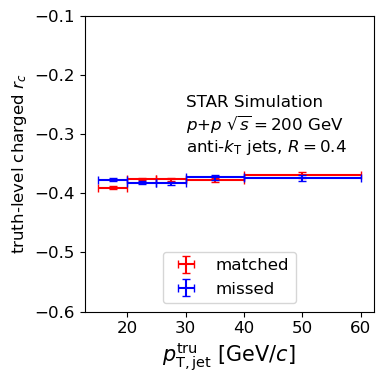

In [10]:
plt.rcParams['font.size'] = 12
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, rc_match, xerr=PT_XERR, yerr=err_match, capsize=3, color='r', ls='none', label='matched')
ax.errorbar(PT_CENTERS, rc_miss, xerr=PT_XERR, yerr=err_miss, capsize=3, color='b', ls='none', label='missed')
ax.set_xlabel(r'$p_{\mathrm{T,jet}}^{\mathrm{tru}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('truth-level charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.legend(loc='lower center')
ax.text(30, -0.33, 'STAR Simulation\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')
plt.tight_layout()